In [3]:
import scanpy as sc      # marker genes, plots, saving
import squidpy as sq     # the tissue map
import pandas as pd      # tables
import numpy as np       # the gap-finding maths

RecursionError: maximum recursion depth exceeded

In [ ]:
proc = "/nobackup/proj/comet_smmnfst/processed/"
adata = sc.read_h5ad(proc + "region1_clustered.h5ad")
adata

AnnData object with n_obs × n_vars = 31312 × 4999
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'leiden', 'leiden_centrality_scores', 'leiden_colors', 'leiden_nhood_enrichment', 'log1p', 'neighbors', 'pca', 'spatial_neighbors', 'spatialdata_attrs', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distance

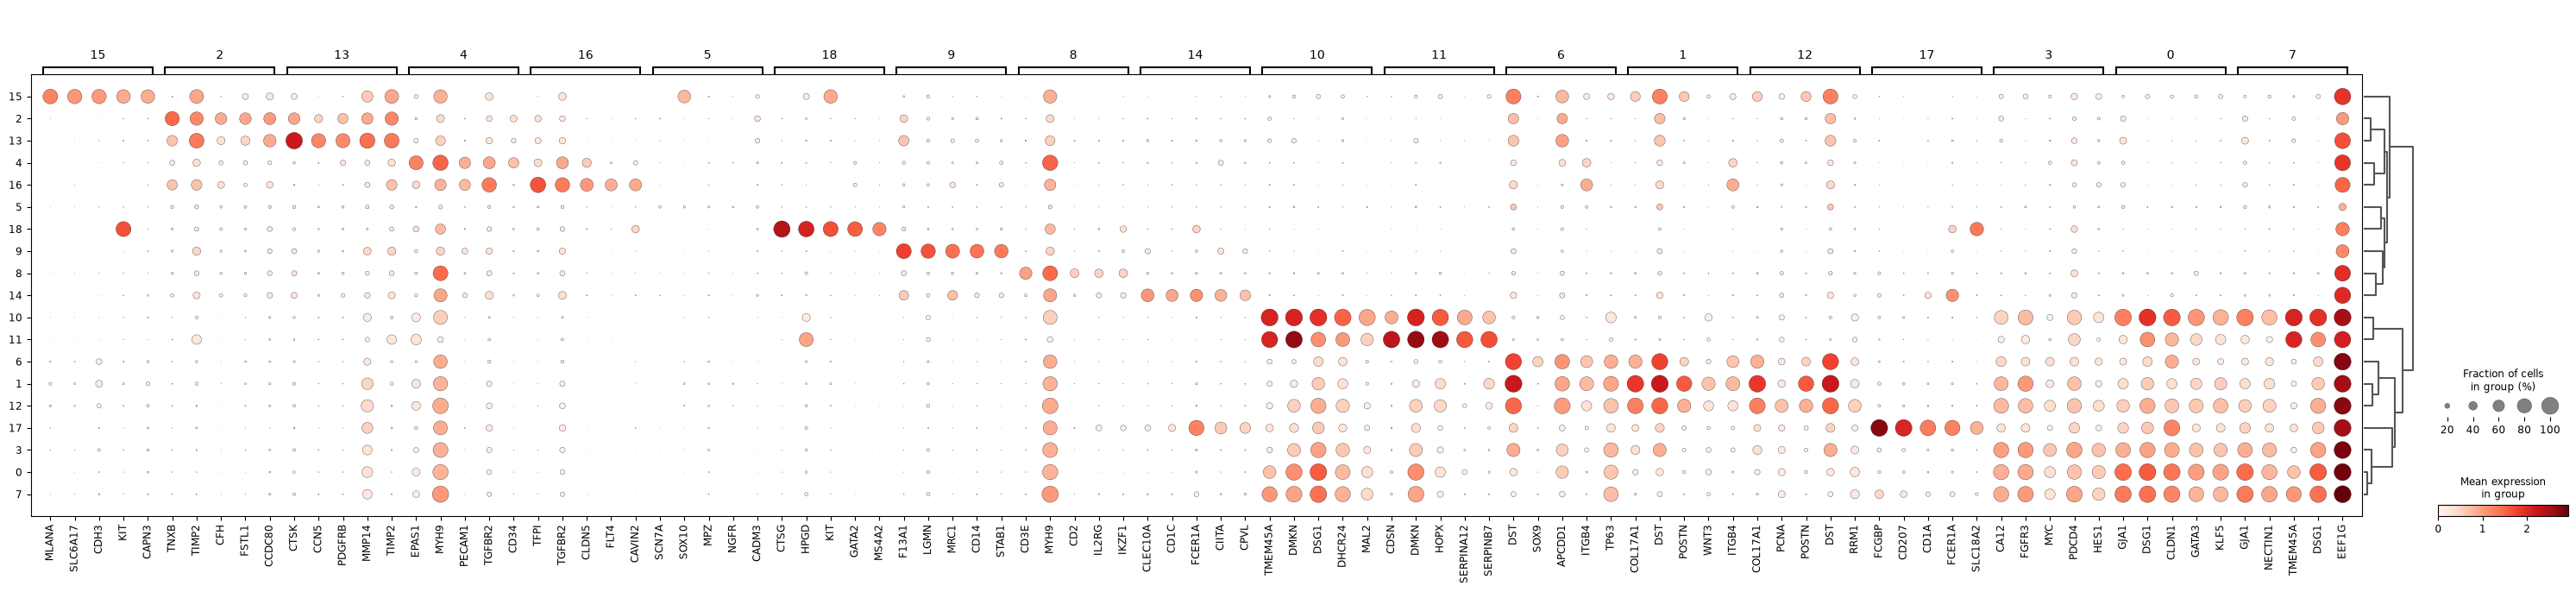

In [ ]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(adata, n_genes=5)

In [ ]:
sc.get.rank_genes_groups_df(adata, group="0").head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,GJA1,82.114510,2.622912,0.0,0.0
1,DSG1,81.461174,2.616078,0.0,0.0
2,CLDN1,75.481651,2.379115,0.0,0.0
3,GATA3,70.265831,2.194464,0.0,0.0
4,KLF5,69.448326,2.157391,0.0,0.0
5,DMKN,68.320862,1.988166,0.0,0.0
6,CCND1,63.667480,2.081673,0.0,0.0
7,ANO1,62.162186,2.372544,0.0,0.0
8,CCL27,60.259464,1.945135,0.0,0.0
9,CDHR1,59.981781,2.023538,0.0,0.0


In [ ]:
top = {}
for c in adata.obs["leiden"].cat.categories:
    top[c] = sc.get.rank_genes_groups_df(adata, group=c).head(20)["names"].tolist()

top_genes = pd.DataFrame(top)
top_genes



,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
0,GJA1,COL17A1,TNXB,CA12,EPAS1,SCN7A,DST,GJA1,CD3E,F13A1,TMEM45A,CDSN,COL17A1,CTSK,CLEC10A,MLANA,TFPI,FCGBP,CTSG
1,DSG1,DST,TIMP2,FGFR3,MYH9,SOX10,SOX9,NECTIN1,MYH9,LGMN,DMKN,DMKN,PCNA,CCN5,CD1C,SLC6A17,TGFBR2,CD207,HPGD
2,CLDN1,POSTN,CFH,MYC,PECAM1,MPZ,APCDD1,TMEM45A,CD2,MRC1,DSG1,HOPX,POSTN,PDGFRB,FCER1A,CDH3,CLDN5,CD1A,KIT
3,GATA3,WNT3,FSTL1,PDCD4,TGFBR2,NGFR,ITGB4,DSG1,IL2RG,CD14,DHCR24,SERPINA12,DST,MMP14,CIITA,KIT,FLT4,FCER1A,GATA2
4,KLF5,ITGB4,CCDC80,HES1,CD34,CADM3,TP63,EEF1G,IKZF1,STAB1,MAL2,SERPINB7,RRM1,TIMP2,CPVL,CAPN3,CAVIN2,SLC18A2,MS4A2
5,DMKN,COL7A1,TWIST2,FAT2,PLVAP,L1CAM,HNRNPA1L2,CLDN1,SEPTIN9,SLC40A1,LGALSL,CSNK2A2,TUBB,LEPR,ITGB2,MITF,RELN,CSF1R,SLC18A2
6,CCND1,TP63,TWIST1,EEF1G,CLDN5,NCAM1,COL17A1,ALDH2,HSPA8,CTSC,HOPX,KPRP,APCDD1,DPP4,IFNGR1,DCT,PECAM1,CIITA,CMA1
7,ANO1,SLC2A1,CTSK,NECTIN1,NRN1,GRIK3,EEF1G,FGFR3,ITGB2,CCL13,EMP2,TMEM45A,PRXL2A,TWIST1,CD4,CD59,ITGB4,CLDN1,SIGLEC6
8,CCL27,FGFR3,LEPR,CDHR1,SHANK3,MAL,IL11RA,CDH1,CXCR4,SLCO2B1,SEPTIN5,IDE,ANO1,SLC29A1,IL13RA1,SOX10,PROX1,CPVL,HDC
9,CDHR1,PRXL2A,COL5A1,NOTCH1,CCL14,CNTN2,ABI3BP,PTGS1,ITGAL,CCL18,EGR3,ITPRID2,TYMS,CCDC80,MRC1,BACE2,SH3BGRL2,PTPN6,IL1RL1


In [ ]:
top_genes.to_csv(proc + "top20_genes_per_cluster.csv")

/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spat

/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spat

/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spat

/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spat

/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spat

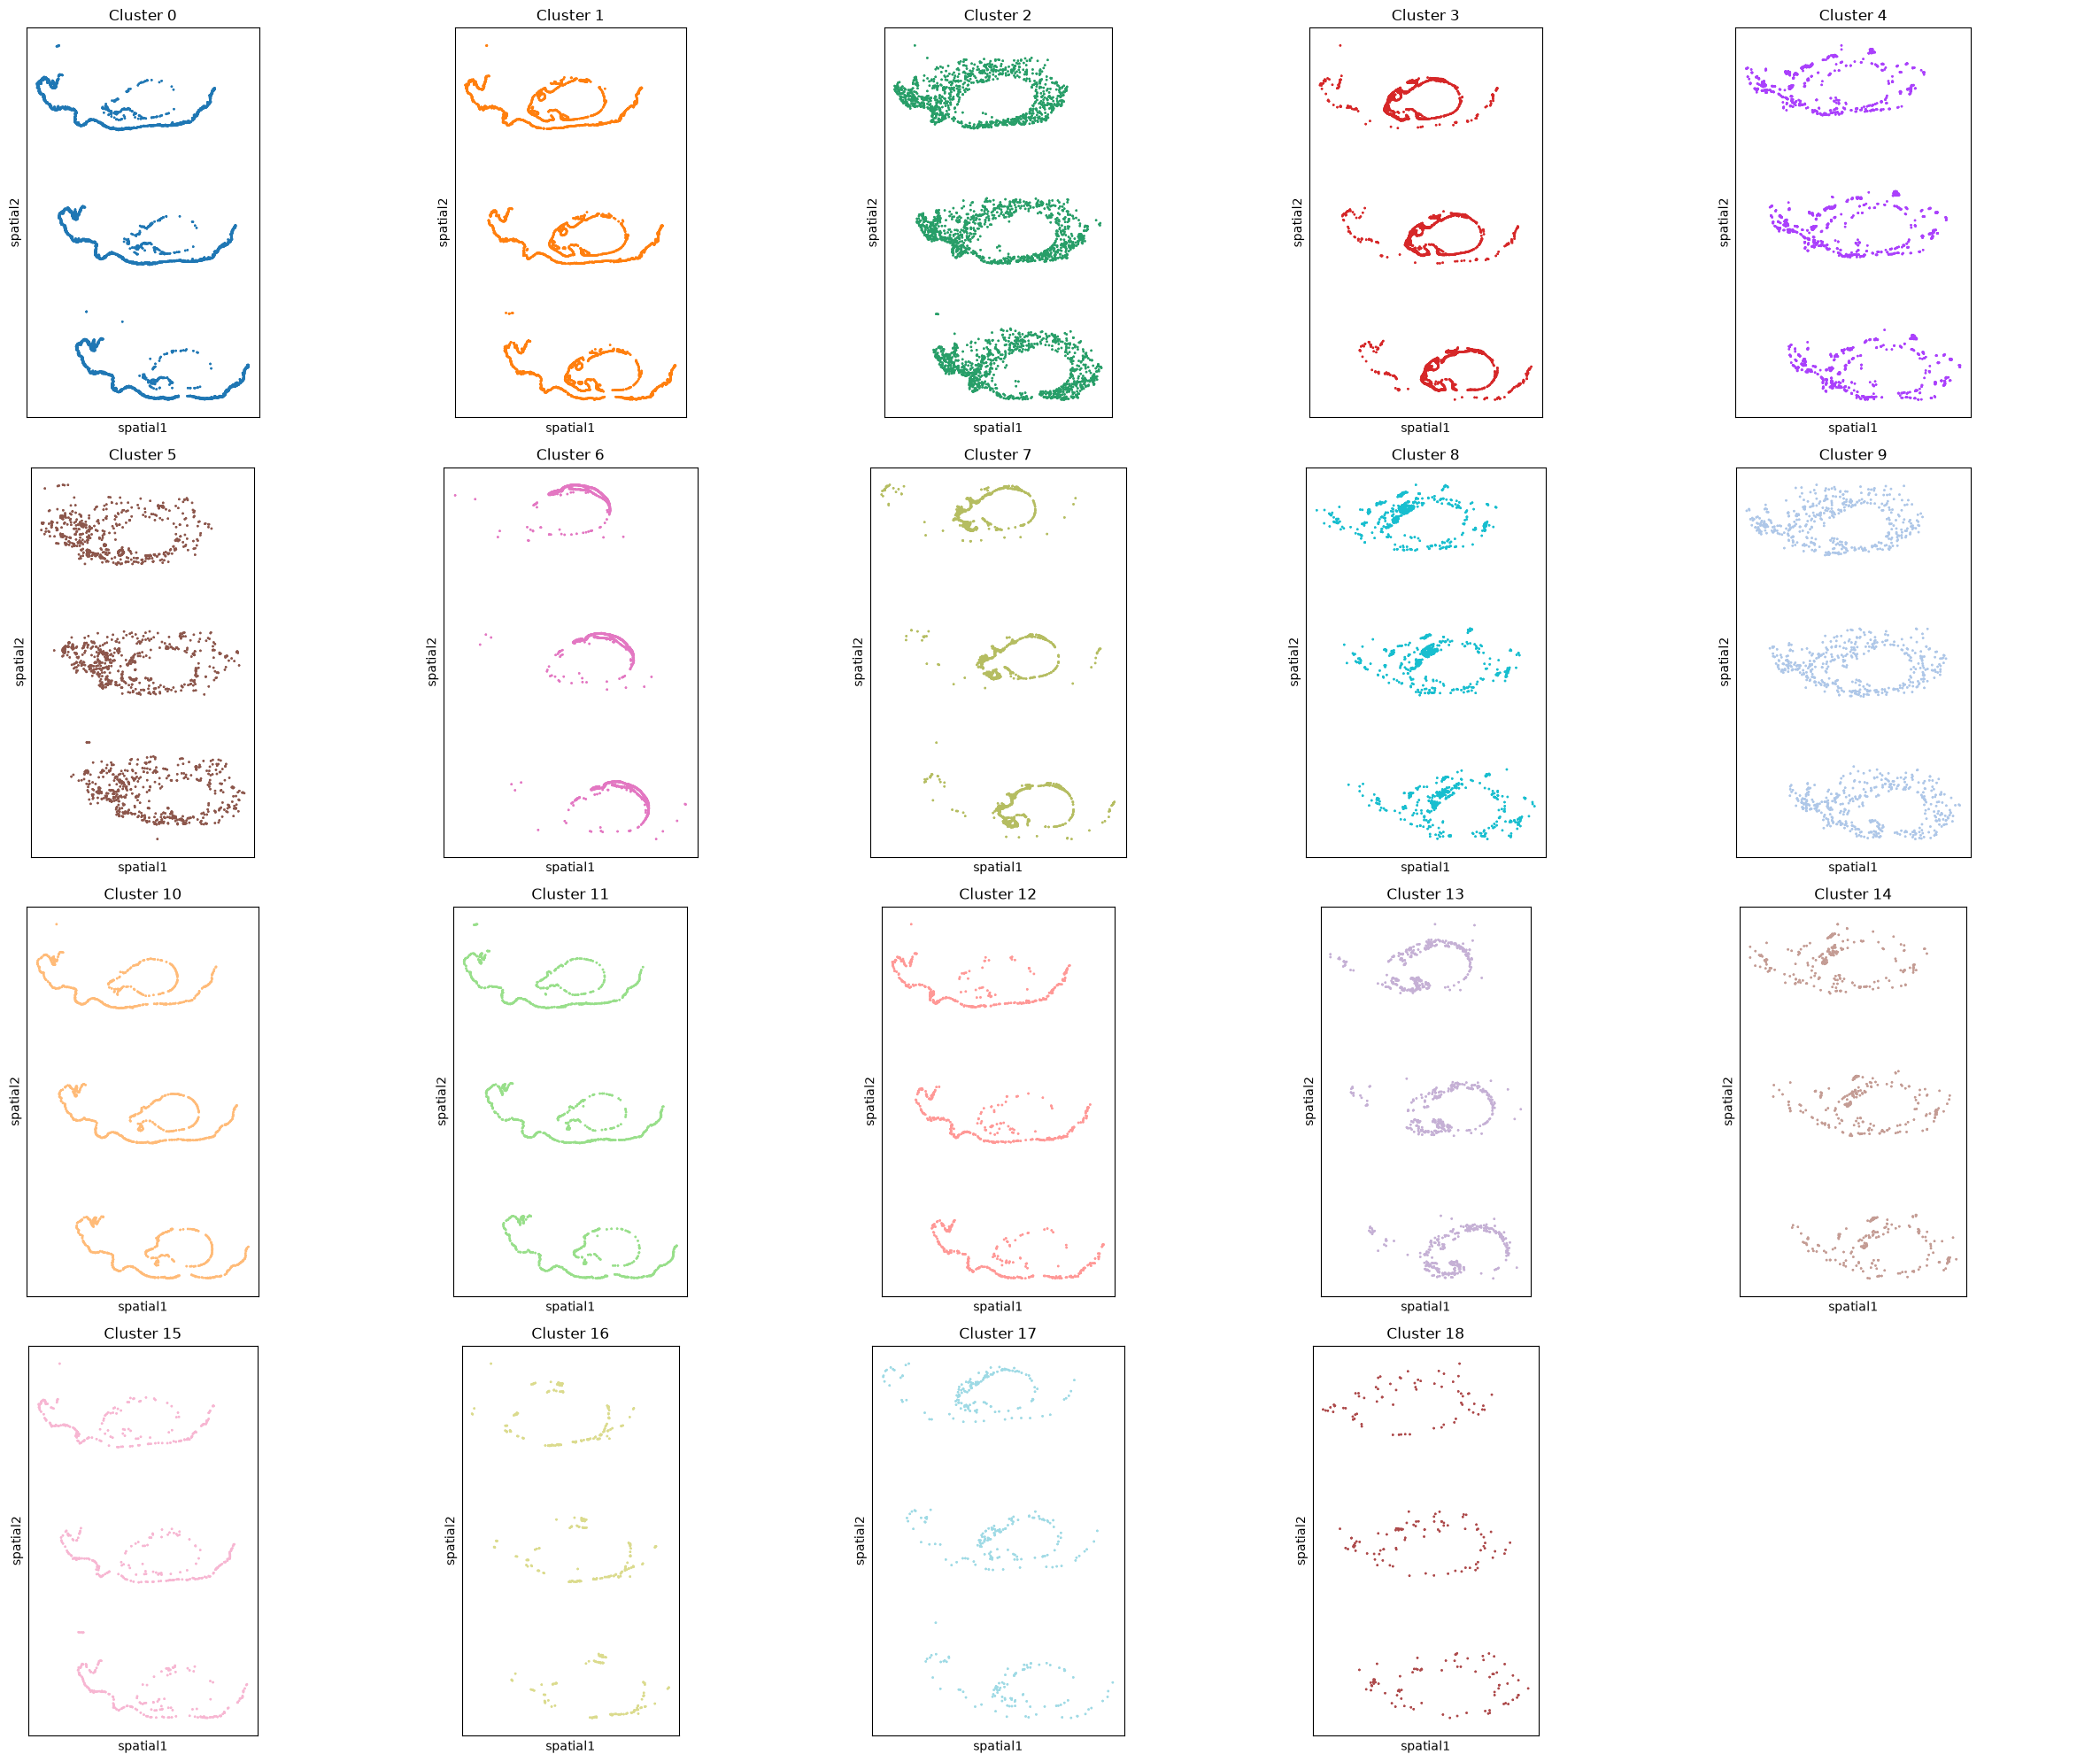

In [ ]:
import matplotlib.pyplot as plt

clusters = adata.obs["leiden"].cat.categories          # all 19, in order
fig, axs = plt.subplots(4, 5, figsize=(25, 20))        # grid of 4 rows × 5 columns
for ax, c in zip(axs.flat, clusters):
    sq.pl.spatial_scatter(adata, color="leiden", groups=[c], shape=None, size=3,
                          ax=ax, title=f"Cluster {c}", legend_loc=None)
axs.flat[-1].axis("off")                                # hide the spare 20th panel
plt.tight_layout()

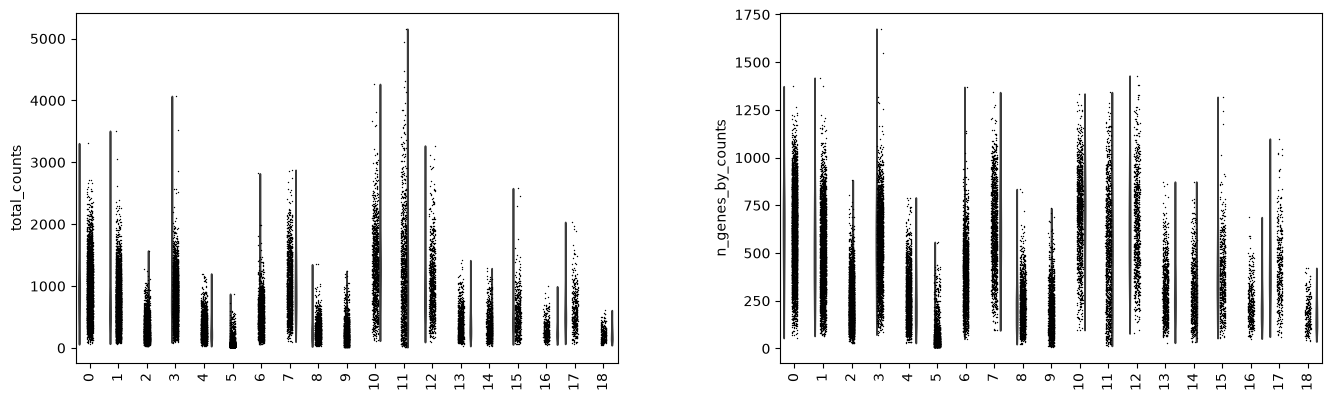

In [ ]:
qc = adata.obs.groupby("leiden")[["total_counts", "n_genes_by_counts", "cell_area"]].median()
qc["n_cells"] = adata.obs["leiden"].value_counts()
qc.sort_values("total_counts")

sc.pl.violin(adata, ["total_counts", "n_genes_by_counts"], groupby="leiden", rotation=90)

In [ ]:
names = {
    "0":  "Spinous keratinocyte",
    "1":  "Basal keratinocyte",
    "2":  "Fibroblast reticular (PI16+)",
    "3":  "Basal-to-spinous keratinocyte",
    "4":  "Endothelial blood",
    "5":  "Schwann / nerve",
    "6":  "Hair follicle ORS basal (SOX9+)",
    "7":  "Spinous keratinocyte upper",
    "8":  "T cell",
    "9":  "Macrophage",
    "10": "Upper spinous / early granular",
    "11": "Granular / cornified keratinocyte",
    "12": "Basal keratinocyte proliferating",
    "13": "Fibroblast papillary (FAP+ DPP4+)",
    "14": "Dendritic cell (cDC2)",
    "15": "Melanocyte",
    "16": "Endothelial lymphatic",
    "17": "Langerhans cell",
    "18": "Mast cell",
}

adata.obs["cell_type"] = adata.obs["leiden"].map(names).astype("category")
adata.obs["cell_type"].value_counts()

cell_type
Spinous keratinocyte                 4338
Basal keratinocyte                   3727
Fibroblast reticular (PI16+)         3263
Basal-to-spinous keratinocyte        3128
Endothelial blood                    2194
Schwann / nerve                      1897
Hair follicle ORS basal (SOX9+)      1751
Spinous keratinocyte upper           1558
T cell                               1516
Macrophage                           1311
Upper spinous / early granular       1309
Granular / cornified keratinocyte    1208
Basal keratinocyte proliferating      918
Fibroblast papillary (FAP+ DPP4+)     907
Dendritic cell (cDC2)                 657
Melanocyte                            593
Endothelial lymphatic                 399
Langerhans cell                       397
Mast cell                             241
Name: count, dtype: int64

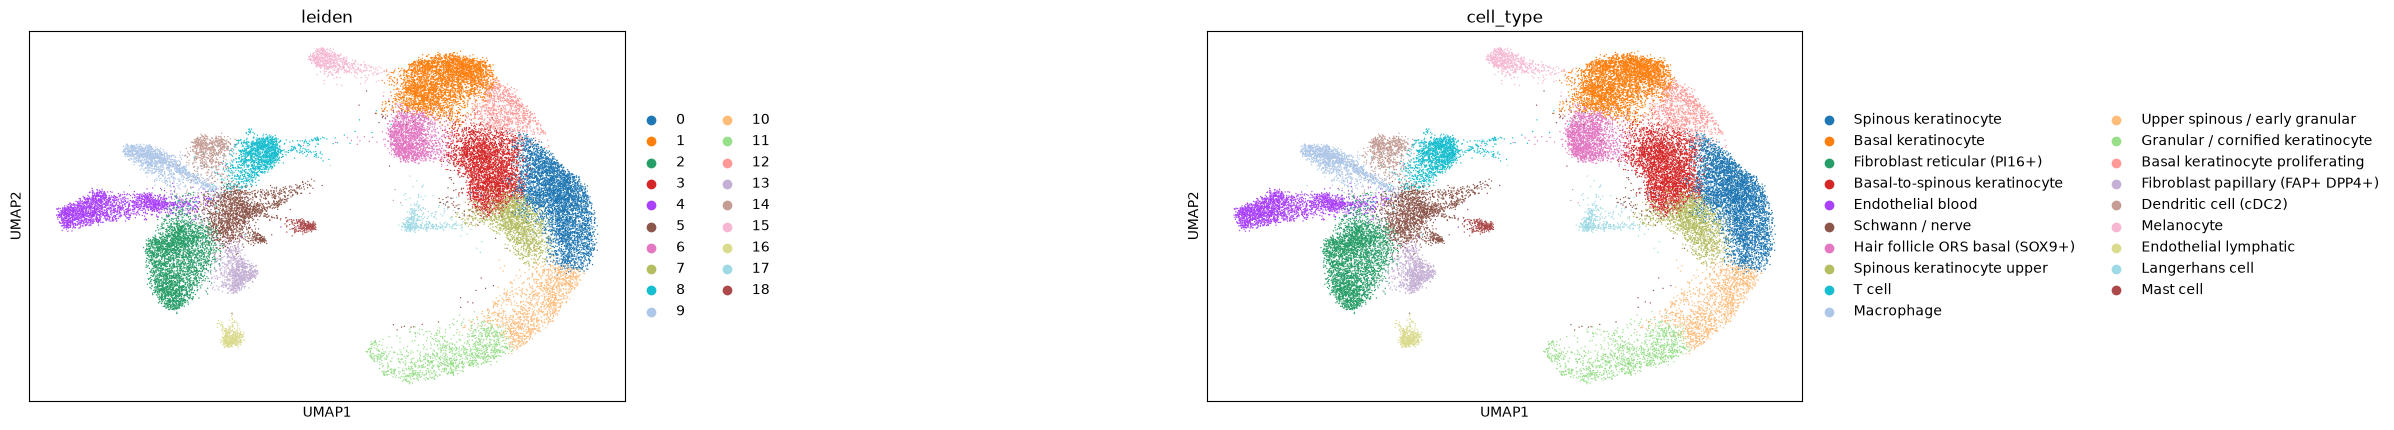

/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:468: FutureWarning: The method obs_vector is deprecated and will be removed in the future. Use anndata.acc.A instead of obs_vector. E.g. `vec = adata[A.obs['foo']]` or `vec = adata[A.layers['l']['bar', :]]`
  color_source_vector = adata.obs_vector(value_to_plot, layer=layer)
/mnt/nfs/home/nmtr1/.local/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:979: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


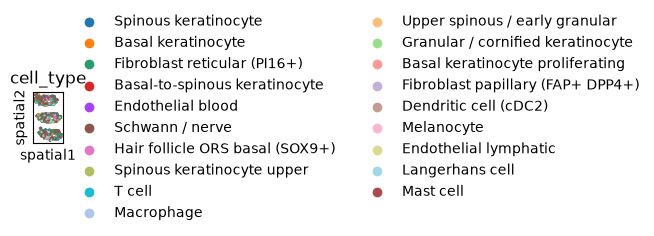

In [ ]:
sc.pl.umap(adata, color=["leiden", "cell_type"], wspace=0.8)
sq.pl.spatial_scatter(adata, color="cell_type", shape=None, size=2)

In [ ]:
adata.write(proc + "region1_annotated.h5ad")